# Histograms

In [1]:
# datascience
from datascience import *
import numpy as np
import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
plots.rcParams["patch.force_edgecolor"] = True


In [2]:
# polars
import polars as pl
from IPython.display import display
import hvplot.polars


## Use counts and bar charts for categorical distributions

In [3]:
# datascience
top_movies_2017 = Table.read_table('top_movies_2017.csv')
top_movies_2017.show(6)


Title,Studio,Gross,Gross (Adjusted),Year
Gone with the Wind,MGM,198676459,1796176700,1939
Star Wars,Fox,460998007,1583483200,1977
The Sound of Music,Fox,158671368,1266072700,1965
E.T.: The Extra-Terrestrial,Universal,435110554,1261085000,1982
Titanic,Paramount,658672302,1204368000,1997
The Ten Commandments,Paramount,65500000,1164590000,1956


In [4]:
# polars
top_movies_2017_pl = pl.read_csv('top_movies_2017.csv', eol_char='\r')
top_movies_2017_pl.head(6)


Title,Studio,Gross,Gross (Adjusted),Year
str,str,i64,i64,i64
"""Gone with the Wind""","""MGM""",198676459,1796176700,1939
"""Star Wars""","""Fox""",460998007,1583483200,1977
"""The Sound of Music""","""Fox""",158671368,1266072700,1965
"""E.T.: The Extra-Terrestrial""","""Universal""",435110554,1261085000,1982
"""Titanic""","""Paramount""",658672302,1204368000,1997
"""The Ten Commandments""","""Paramount""",65500000,1164590000,1956


In [5]:
# TODO: visualize distribution of Studios

Exercise: Show the **percentage** of movies from each studio instead of the count

In [6]:
# TODO: your answer here

## Use binning for numerical distributions

In [7]:
# datascience
# Data from https://www.boxofficemojo.com/chart/ww_top_lifetime_gross/
top_movies = Table.read_table('top_movies_2026.csv')
top_movies.show(4)


Title,Worldwide Lifetime Gross,Domestic Lifetime Gross,Foreign Lifetime Gross,Year
Avatar,2923710708,785221649,2138489059,2009
Avengers: Endgame,2799439100,858373000,1941066100,2019
Avatar: The Way of Water,2334484620,688459501,1646025119,2022
Titanic,2264812968,674354882,1590458086,1997


In [8]:
# polars
# Data from https://www.boxofficemojo.com/chart/ww_top_lifetime_gross/
top_movies_pl = pl.read_csv('top_movies_2026.csv')
top_movies_pl.head(4)


Title,Worldwide Lifetime Gross,Domestic Lifetime Gross,Foreign Lifetime Gross,Year
str,i64,i64,i64,i64
"""Avatar""",2923710708,785221649,2138489059,2009
"""Avengers: Endgame""",2799439100,858373000,1941066100,2019
"""Avatar: The Way of Water""",2334484620,688459501,1646025119,2022
"""Titanic""",2264812968,674354882,1590458086,1997


Optional: `datascience` [Formatters](https://data8.org/datascience/formats.html)

In [9]:
# datascience
top_movies.set_format(3, CurrencyFormatter)


Title,Worldwide Lifetime Gross,Domestic Lifetime Gross,Foreign Lifetime Gross,Year
Avatar,2923710708,785221649,"$2,138,489,059",2009
Avengers: Endgame,2799439100,858373000,"$1,941,066,100",2019
Avatar: The Way of Water,2334484620,688459501,"$1,646,025,119",2022
Titanic,2264812968,674354882,"$1,590,458,086",1997
Ne Zha 2,2259822417,23308176,"$2,236,514,241",2025
Star Wars: Episode VII - The Force Awakens,2071310218,936662225,"$1,134,647,993",2015
Avengers: Infinity War,2052415039,678815482,"$1,373,599,557",2018
Spider-Man: No Way Home,1921426073,814866759,"$1,106,559,314",2021
Zootopia 2,1778775365,410218402,"$1,368,556,963",2025
Inside Out 2,1698863816,652980194,"$1,045,883,622",2024


In [10]:
# polars
top_movies_pl


Title,Worldwide Lifetime Gross,Domestic Lifetime Gross,Foreign Lifetime Gross,Year
str,i64,i64,i64,i64
"""Avatar""",2923710708,785221649,2138489059,2009
"""Avengers: Endgame""",2799439100,858373000,1941066100,2019
"""Avatar: The Way of Water""",2334484620,688459501,1646025119,2022
"""Titanic""",2264812968,674354882,1590458086,1997
"""Ne Zha 2""",2259822417,23308176,2236514241,2025
…,…,…,…,…
"""Casino Royale""",616585752,167445960,449139792,2006
"""The Wandering Earth II""",615023132,5023132,610000000,2023
"""Mamma Mia!""",615015484,144330569,470684915,2008


In [11]:
# TODO: explore data

In [12]:
# TODO: what are the outliers?

### **Task**: Visualize the distribution of movie ages

In [13]:
# datascience
ages = 2026 - top_movies.column('Year')
ages


array([17,  7,  4, 29,  1, 11,  8,  5,  1,  2, 11,  7, 14, 11,  4,  7,  3,
        1, 11,  3,  8, 15,  2,  9,  8, 13,  9,  8,  9, 13, 11, 10,  8, 23,
        7,  7, 15, 14, 12, 33, 14,  7,  7,  7, 16, 20,  2, 10,  7, 15, 27,
        1,  9, 25, 10, 10, 16, 14, 18,  4, 32,  3,  2, 13, 10, 12,  9, 19,
       16, 13,  1,  4, 24, 19, 23, 17,  4, 22,  8, 21,  5, 21, 25, 19, 17,
       24,  9, 11, 14, 10, 10,  9,  1, 14, 13,  9,  4, 11,  8,  9,  3, 16,
       17,  8,  9,  9,  5, 30, 10, 24, 22, 19,  7, 20, 44,  9, 17, 13, 18,
        8, 22, 10, 49,  5, 12, 12,  4,  4,  7, 16, 12, 12,  2, 14, 16, 10,
       14, 12, 21, 13, 23, 17, 15,  1,  5,  7, 13,  2,  9, 12,  2, 12, 17,
       11, 12, 19,  3,  7, 14, 15,  3,  5, 32, 10, 27, 12,  3, 13, 20, 15,
       11,  9,  8, 23, 14, 24, 13, 10,  1,  3, 10, 18,  1, 22, 11, 18,  4,
       15, 16, 19,  8, 12,  9, 29,  1, 20,  3, 18, 22, 14])

In [14]:
# polars
ages_pl = 2026 - top_movies_pl.get_column('Year')
ages_pl


Year
i64
17
7
4
29
1
…
20
3
18


In [15]:
# datascience
top_movies = top_movies.with_column('Age', ages)
top_movies


Title,Worldwide Lifetime Gross,Domestic Lifetime Gross,Foreign Lifetime Gross,Year,Age
Avatar,2923710708,785221649,"$2,138,489,059",2009,17
Avengers: Endgame,2799439100,858373000,"$1,941,066,100",2019,7
Avatar: The Way of Water,2334484620,688459501,"$1,646,025,119",2022,4
Titanic,2264812968,674354882,"$1,590,458,086",1997,29
Ne Zha 2,2259822417,23308176,"$2,236,514,241",2025,1
Star Wars: Episode VII - The Force Awakens,2071310218,936662225,"$1,134,647,993",2015,11
Avengers: Infinity War,2052415039,678815482,"$1,373,599,557",2018,8
Spider-Man: No Way Home,1921426073,814866759,"$1,106,559,314",2021,5
Zootopia 2,1778775365,410218402,"$1,368,556,963",2025,1
Inside Out 2,1698863816,652980194,"$1,045,883,622",2024,2


In [16]:
# polars
top_movies_pl = top_movies_pl.with_columns((ages_pl).alias('Age'))
top_movies_pl


Title,Worldwide Lifetime Gross,Domestic Lifetime Gross,Foreign Lifetime Gross,Year,Age
str,i64,i64,i64,i64,i64
"""Avatar""",2923710708,785221649,2138489059,2009,17
"""Avengers: Endgame""",2799439100,858373000,1941066100,2019,7
"""Avatar: The Way of Water""",2334484620,688459501,1646025119,2022,4
"""Titanic""",2264812968,674354882,1590458086,1997,29
"""Ne Zha 2""",2259822417,23308176,2236514241,2025,1
…,…,…,…,…,…
"""Casino Royale""",616585752,167445960,449139792,2006,20
"""The Wandering Earth II""",615023132,5023132,610000000,2023,3
"""Mamma Mia!""",615015484,144330569,470684915,2008,18


In [17]:
min(ages), max(ages)

(1, 49)

- If you want to make equally sized bins, `np.arange()` is a great tool to help you.

In [18]:
# datascience
np.arange(0, max(ages)+10, 10)


array([ 0, 10, 20, 30, 40, 50])

In [19]:
# polars
pl.int_range(0, max(ages_pl)+10, 10, eager=True)


literal
i64
0
10
20
30
40
50


In [20]:
# TODO: use bin method

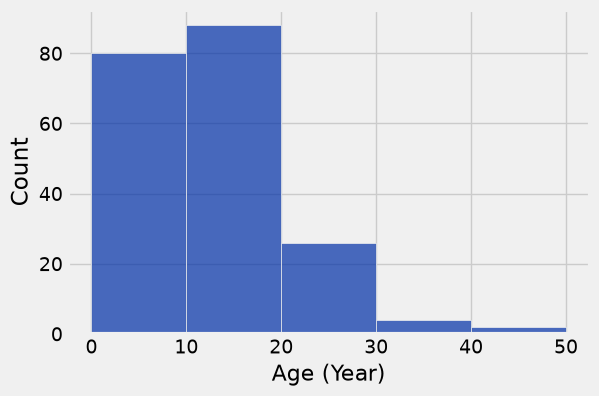

In [21]:
# datascience
top_movies.hist('Age', bins = np.arange(0, max(ages)+10, 10), unit = 'Year', normed=False)


In [22]:
# polars
# hvplot
top_movies_pl.hvplot.hist(y='Age', normed=False, bins=(pl.int_range(0, max(ages_pl)+10, 10, eager=True)).to_list(), xlabel='Age (Year)')


:Histogram   [Age]   (Count)

---

- Otherwise, you can pick your own bins. These are just bins that we picked out.


In [23]:
# datascience
my_bins = make_array(0, 5, 10, 15, 25, 60)


In [24]:
# polars
my_bins_pl = pl.Series('values', [0, 5, 10, 15, 25, 60])


In [25]:
# datascience
binned_data = top_movies.bin('Age', bins = my_bins)
binned_data


bin,Age count
0,35
5,45
10,56
15,52
25,12
60,0


In [26]:
# polars
binned_data_pl = top_movies_pl.get_column('Age').hist(bins=(my_bins_pl).to_list()).rename({'breakpoint': 'bin', 'count': 'Age count'}).drop('category')
binned_data_pl


bin,Age count
f64,u32
5.0,41
10.0,52
15.0,50
25.0,47
60.0,10


**Note:** The last "bin" does not include any observations!!

## Introducing the histogram and the area principle

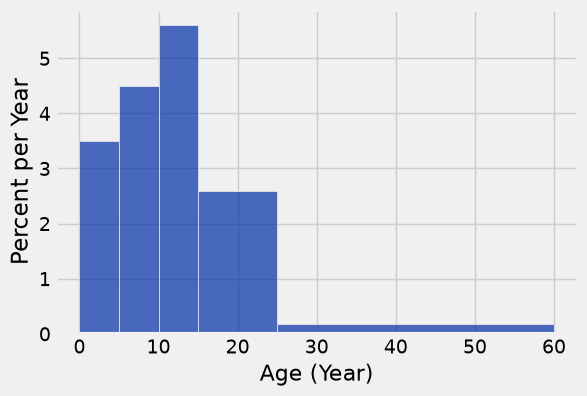

In [27]:
# datascience
top_movies.hist('Age', bins = my_bins, unit = 'Year', normed=True)


In [28]:
# polars
# hvplot
top_movies_pl.hvplot.hist(y='Age', normed=True, bins=(my_bins_pl).to_list(), xlabel='Age (Year)')


:Histogram   [Age]   (Frequency)

---

### **Discussion Question**: Compare the bins $[0, 5)$ and $[15, 25)$. 

- Which one has more movies?
- Which one is more crowded?

## Challenge tasks

### **Task**: Find the height of the $[15,25)$ bin in the histogram above.

$$\text{height} = \frac{\text{percent}}{\text{width}}$$

Add a column containing what percent of movies are in each bin (the **area** of each bin)

In [29]:
# TODO

In [30]:
# TODO

In [31]:
# TODO

In [32]:
# TODO

In [33]:
# TODO

### **Task**: Find the heights of the (rest of the) bins.

$$\text{height} = \frac{\text{percent}}{\text{width}}$$

Remember that the last row in the table does not represent a bin!

In [34]:
# datascience
height_table = binned_data.take(np.arange(binned_data.num_rows - 1))
height_table 


bin,Age count
0,35
5,45
10,56
15,52
25,12


In [35]:
# polars
height_table_pl = binned_data_pl.gather(pl.int_range(binned_data_pl.height - 1, eager=True))
height_table_pl 


bin,Age count
f64,u32
5.0,41
10.0,52
15.0,50
25.0,47


Remember `np.diff`?

In [36]:
# datascience
bin_widths = np.diff(binned_data.column('bin'))


In [37]:
# polars
bin_widths_pl = (binned_data_pl.get_column('bin')).diff(null_behavior='drop')


In [38]:
bin_widths

array([ 5,  5,  5, 10, 35])

In [39]:
# datascience
height_table = height_table.with_column('Width', bin_widths)
height_table


bin,Age count,Width
0,35,5
5,45,5
10,56,5
15,52,10
25,12,35


In [40]:
# polars
height_table_pl = height_table_pl.with_columns((bin_widths_pl).alias('Width'))
height_table_pl


bin,Age count,Width
f64,u32,f64
5.0,41,5.0
10.0,52,5.0
15.0,50,10.0
25.0,47,35.0


In [41]:
# datascience
height_table = height_table.with_column('Height',
                                        height_table.column('Percent')/height_table.column('Width'))


ValueError: The column "Percent" is not in the table. The table contains these columns: bin, Age count, Width

In [42]:
# polars
height_table_pl = height_table_pl.with_columns((height_table_pl.get_column('Percent')/height_table_pl.get_column('Width')).alias('Height'))


ColumnNotFoundError: "Percent" not found

In [43]:
height_table

bin,Age count,Width
0,35,5
5,45,5
10,56,5
15,52,10
25,12,35


To check our work one last time, let's see if the numbers in the last column match the heights of the histogram:

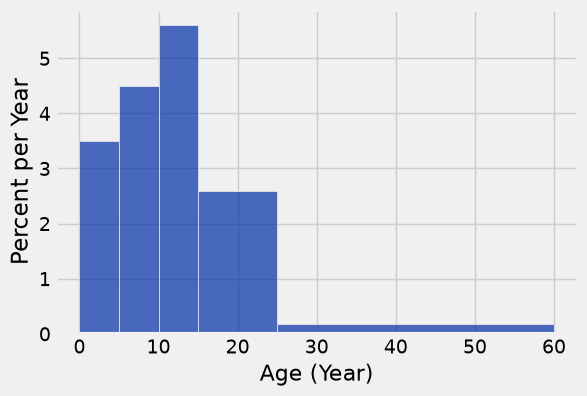

In [44]:
# datascience
top_movies.hist('Age', bins = my_bins, unit = 'Year')


In [45]:
# polars
# hvplot
top_movies_pl.hvplot.hist(y='Age', normed=True, bins=(my_bins_pl).to_list(), xlabel='Age (Year)')


:Histogram   [Age]   (Frequency)